# Paper 2: A Confidence-Driven Adaptive Multi-Sensor Fusion Framework for Robust Autonomous Vehicle Localization

## Notebook 01 - Dataset Validation

### Objective

This notebook validates the KITTI Odometry dataset before any preprocessing or sensor fusion.

The notebook performs the following tasks:

- Verify dataset directory structure
- Validate sequence availability
- Verify calibration files
- Verify stereo color images
- Verify ground-truth pose files
- Check missing data
- Generate dataset statistics
- Produce a validation report

The output of this notebook confirms whether the dataset is ready for subsequent stages of the proposed framework.

In [1]:
import os
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display

plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["figure.dpi"] = 120

In [2]:
# ============================================================
# DATASET PATHS
# ============================================================

ROOT_DIR = Path(r"D:\Research\Papers\Paper_2\datasets\KITTI_Odometry")

COLOR_DIR = ROOT_DIR / "data_odometry_color" / "dataset" / "sequences"

CALIB_DIR = ROOT_DIR / "data_odometry_calib" / "dataset" / "sequences"

POSE_DIR = ROOT_DIR / "data_odometry_poses" / "dataset" / "poses"

RESULT_DIR = Path("../results/dataset_validation")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Root :", ROOT_DIR)
print("Color:", COLOR_DIR)
print("Calib:", CALIB_DIR)
print("Pose :", POSE_DIR)

Root : D:\Research\Papers\Paper_2\datasets\KITTI_Odometry
Color: D:\Research\Papers\Paper_2\datasets\KITTI_Odometry\data_odometry_color\dataset\sequences
Calib: D:\Research\Papers\Paper_2\datasets\KITTI_Odometry\data_odometry_calib\dataset\sequences
Pose : D:\Research\Papers\Paper_2\datasets\KITTI_Odometry\data_odometry_poses\dataset\poses


In [3]:
paths = {
    "Color Dataset": COLOR_DIR,
    "Calibration": CALIB_DIR,
    "Ground Truth": POSE_DIR,
}

print("="*60)

for name, path in paths.items():

    if path.exists():
        print(f"✓ {name:<20} FOUND")
    else:
        print(f"✗ {name:<20} MISSING")

print("="*60)

✓ Color Dataset        FOUND
✓ Calibration          FOUND
✓ Ground Truth         FOUND


In [4]:
sequence_dirs = sorted(
    [d.name for d in COLOR_DIR.iterdir() if d.is_dir()]
)

print(f"Total Sequences : {len(sequence_dirs)}")

print(sequence_dirs)

Total Sequences : 22
['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21']


In [5]:
records = []

for seq in sequence_dirs:

    image_dir = COLOR_DIR / seq / "image_2"
    calib_file = CALIB_DIR / seq / "calib.txt"
    pose_file = POSE_DIR / f"{seq}.txt"

    image_count = len(list(image_dir.glob("*.png")))

    if pose_file.exists():
        dataset_type = "Training"
    else:
        dataset_type = "Testing"

    records.append({
        "Sequence": seq,
        "Dataset Type": dataset_type,
        "Images": image_count,
        "Calibration": calib_file.exists(),
        "Ground Truth": pose_file.exists()
    })

validation_df = pd.DataFrame(records)

display(validation_df)

,Sequence,Dataset Type,Images,Calibration,Ground Truth
0,00,Training,4541,True,True
1,01,Training,1101,True,True
2,02,Training,4661,True,True
3,03,Training,801,True,True
4,04,Training,271,True,True
5,05,Training,2761,True,True
6,06,Training,1101,True,True
7,07,Training,1101,True,True
8,08,Training,4071,True,True
9,09,Training,1591,True,True


In [6]:
total_sequences = len(validation_df)

training_sequences = validation_df["Ground Truth"].sum()

testing_sequences = total_sequences - training_sequences

total_images = validation_df["Images"].sum()

summary_df = pd.DataFrame({

    "Metric":[
        "Total Sequences",
        "Training Sequences",
        "Testing Sequences",
        "Total Images",
        "Calibration Files"
    ],

    "Value":[
        total_sequences,
        training_sequences,
        testing_sequences,
        total_images,
        validation_df["Calibration"].sum()
    ]

})

display(summary_df)

,Metric,Value
0,Total Sequences,22
1,Training Sequences,11
2,Testing Sequences,11
3,Total Images,43552
4,Calibration Files,22


In [7]:
validation_df.to_csv(
    RESULT_DIR / "dataset_validation_report.csv",
    index=False
)

summary_df.to_csv(
    RESULT_DIR / "dataset_summary.csv",
    index=False
)

print("Validation reports saved successfully.")

Validation reports saved successfully.


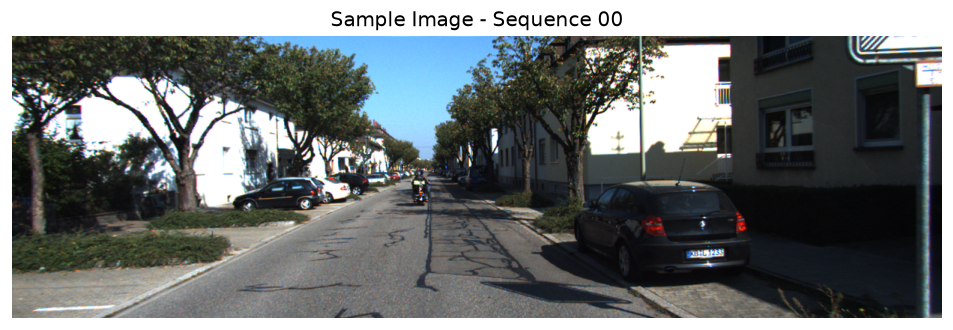

In [8]:
sample_image = COLOR_DIR / "00" / "image_2" / "000000.png"

image = cv2.imread(str(sample_image))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 4))
plt.imshow(image)
plt.title("Sample Image - Sequence 00")
plt.axis("off")
plt.show()

In [9]:
pose_path = POSE_DIR / "00.txt"

poses = pd.read_csv(
    pose_path,
    sep=" ",
    header=None
)

poses.columns = [
    "r11","r12","r13","tx",
    "r21","r22","r23","ty",
    "r31","r32","r33","tz"
]

display(poses.head())

,r11,r12,r13,tx,r21,r22,r23,ty,r31,r32,r33,tz
0,1.000000,9.043680e-12,2.326809e-11,5.551115e-17,9.043683e-12,1.000000,2.392370e-10,3.330669e-16,2.326810e-11,2.392370e-10,1.000000,-4.440892e-16
1,0.999998,5.272628e-04,-2.066935e-03,-4.690294e-02,-5.296506e-04,0.999999,-1.154865e-03,-2.839928e-02,2.066324e-03,1.155958e-03,0.999997,8.586941e-01
2,0.999991,1.048972e-03,-4.131348e-03,-9.374345e-02,-1.058514e-03,0.999997,-2.308104e-03,-5.676064e-02,4.128913e-03,2.312456e-03,0.999989,1.716275e+00
3,0.999980,1.566466e-03,-6.198571e-03,-1.406429e-01,-1.587952e-03,0.999993,-3.462706e-03,-8.515762e-02,6.193102e-03,3.472479e-03,0.999975,2.574964e+00
4,0.999964,2.078471e-03,-8.263498e-03,-1.874858e-01,-2.116664e-03,0.999987,-4.615826e-03,-1.135202e-01,8.253797e-03,4.633149e-03,0.999955,3.432648e+00
